<a href="https://colab.research.google.com/github/alimoorreza/CS167-fall26-notes/blob/main/Day21_Training_a_Modular_MLP_with_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS167: Day21

## Training an MLP using PyTorch

#### CS167: Machine Learning, Fall 2026


📜 [Syllabus](https://analytics.drake.edu/~reza/teaching/cs167_fall26/cs167_syllabus_fall26.pdf)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## __Put the Model on Training Device (GPU or CPU)__
We want to accelerate the training process using graphical processing unit (GPU). Fortunately, in Colab we can access for GPU. You need to enable it from _Runtime-->Change runtime type-->GPU or TPU_

In [2]:
# check to see if torch.cuda is available, otherwise it will use CPU
import torch
import torch.nn as nn
import numpy as np
device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)
print(f"Using {device} device")


Using cuda device


#__Building Modular Code for Multilayer Perceptron (MLP)__

<div>
<img src="https://analytics.drake.edu/~reza/teaching/cs167_sp25/notes/images/mlp_network1.png" width=800/>
</div>

A multilayer perceptron is the simplest type of neural network. It consists of perceptrons (aka nodes, neurons) arranged in layers.
Create a network class with two methods:
- _init()_
- _forward()_


#__Load the Dataset for your MLP__

We can easily import some [built-in datasets](https://pytorch.org/vision/stable/datasets.html) from PyTorch's [torchvision.datasets](torchvision.datasets) module
- [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist)
  - each image size: 28x28 grayscale image
  - each image is associated with a label from __10 classes__
  - training set of 60,000 examples and a test set of 10,000 examples

<div>
<img src="https://analytics.drake.edu/~reza/teaching/cs167_fall26/notes/images/fashion-mnist-sprite.png" width=500/>
</div>


In [3]:
import torch
import torch.nn as nn

# torchvision has many deep learning benchmark datasets Fashion-MNIST, CIFAR-10, Caltech-50, etc
import torchvision
import torchvision.datasets as datasets
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt


training_data = datasets.FashionMNIST(
    root="/content/drive/MyDrive/cs167_fall26/datasets", # headsup! You can replace this path so that it points to a directory in your Google Drive
    train=True,
    download=True,
    transform=ToTensor() # specify the feature and label transformations
)

test_data = datasets.FashionMNIST(
    root="/content/drive/MyDrive/cs167_fall26/datasets", # headsup! You can replace this path so that it points to a directory in your Google Drive
    train=False,
    download=True,
    transform=ToTensor()
)


__Explore some sample training images__

In [5]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

#image, label = training_data[10000]
#image, label = training_data[20000]
#image, label = training_data[50000]
image, label = training_data[200]       # training samples are saved in pairs/tuples of (image, label)

print('sample image size: ', image.shape)
print('label of the sample image: ', labels_map[label])

sample image size:  torch.Size([1, 28, 28])
label of the sample image:  Bag


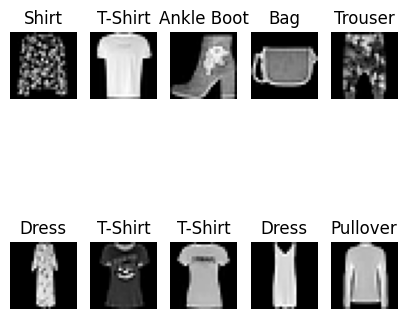

In [6]:
# Visualize a random set of images and their the labels from the training split
# The following labels represent 10 classes, each with specific indices as defined by the creator of the Fashion-MNIST dataset
# reference: https://github.com/zalandoresearch/fashion-mnist#labels

torch.manual_seed(2)
figure = plt.figure(figsize=(5, 5))
cols, rows = 5, 2
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    #print('image tensor size:', img.shape)
    plt.imshow(img.squeeze(), cmap="gray") # .squeeze() method removes the '1' from first dimension of the tensor [1, 28, 28]
    #print('after removing the first dimension with ', img.squeeze().shape)
plt.show()

##__Prepare Your Data with DataLoader for Training/Testing__
We just explored one sample of data at a time. As we have seen in our discussion of the optimizer, specifically __Stochastic Gradient Descent (SGD)__, during training your network, we may need to pass them in __minibatches__. PyTorch has a module called __DataLoader__, which will do this automatically for us as long as we provide the right arguments:
- prepare the __minibatches__ with the given _batch_size_ eg 16, 32, 64, 128, etc
- multiprocessing to speed up the data retrieval
- reshuffle the data at every __epoch__


In [7]:
from torch.utils.data import DataLoader
#                             pairs of items,    minibatch size,       random shuffling turned ON/OFF
train_dataloader = DataLoader(training_data,     batch_size=64,        shuffle=True)  # for training:           it is necessary to shuffle
test_dataloader  = DataLoader(test_data,         batch_size=64,        shuffle=False) # for testing:            it is not necessary to shuffle


Images batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


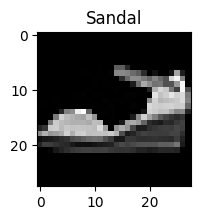

Label id: 5
label of the sample image:  Sandal


In [11]:
# explore the data from the train_dataloader
train_inputs, train_labels = next(iter(train_dataloader)) # returns a batch of 64 train-images and train-labels
print(f"Images batch shape: {train_inputs.shape}")
print(f"Labels batch shape: {train_labels.shape}")

# visualize one of the samples in this batch of 64
figure      = plt.figure(figsize=(2, 2))
img         = train_inputs[15].squeeze()    # I picked 63 but you can pick any index in between 0 to batch_size=63
label       = train_labels[15]              # It's a tensor datatype

plt.title(labels_map[int(label)]) # For indexing, convert the 'tensor' datatype --> integer number datatype
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label id: {label}")
print('label of the sample image: ', labels_map[int(label)])

#__Forward Pass using your Dataset and your MLP__
Test a forward pass of our MLP using one of the training samples. You need to convert a matrix of numbers into a contiguous vector using the following PyTorch module:
- [nn.flatten()](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html)

The forward method inside our network class, __SimpleMLPv2__, will be invoked if we provide an input tensor __'X'__ to the network object we instantiated earlier, i.e., __mlp_model__, as follows:
- _output = mlp_model(X)_

Finally, we convert the ouput from the model into probabilities using __Softmax()__ module:
- _pred_probab = softmax_activation(output)_



In [9]:
import torch
from torch import nn
import pdb

class SimpleMLPv1(nn.Module):
  def __init__(self):
    super().__init__()
    # your network layer construction should take place here
    '''
    num_of_neurons_input_layer      = 784
    num_of_neurons_1st_hidden_layer = 512
    num_of_neurons_2nd_hidden_layer = 256
    num_of_neurons_output_layer     = 10 # usually this number should be equal to the total number of classes in your classification task
    '''
    self.flatten             = nn.Flatten()
    self.my_mlp = nn.Sequential(    nn.Linear(784, 512),                         # linear transformation module (input=784, output=512)
                                    nn.ReLU(),
                                    nn.Linear(512, 256),                         # linear transformation module (input=512, output=256)
                                    nn.ReLU(),
                                    nn.Linear(256, 10))                         # linear transformation module (input=256, output=10)


  def forward(self, x):
    # your code for MLP forward pass should take place here
    x           = self.flatten(x)                                                   # convert a matrix of numbers into a contiguous vector using the following PyTorch module
    print('shape of x: ', x.shape)


    output = self.my_mlp[0](x)
    output = self.my_mlp[1](output)
    print('1st-hidden layer feature map shape: ', output.shape)
    output = self.my_mlp[2](output)
    output = self.my_mlp[3](output)
    print('2nd-hidden layer feature map shape: ', output.shape)
    output = self.my_mlp[4](output)
    print('Output layer feature map shape: ', output.shape)

    return output

# check the structure of your MLP
mlp_model1 = SimpleMLPv1()
print(mlp_model1)

SimpleMLPv1(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (my_mlp): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)


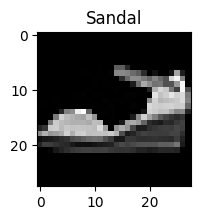

Label id: 5
label of the sample image:  Sandal


In [12]:
index_of_the_sample = 15
# visualize one of the samples in this batch of 64
figure      = plt.figure(figsize=(2, 2))
img         = train_inputs[index_of_the_sample].squeeze()    # I picked 10 but you can pick any index in between 0 to batch_size=63
label       = train_labels[index_of_the_sample]              # It's a tensor datatype

plt.title(labels_map[int(label)]) # For indexing, convert the 'tensor' datatype --> integer number datatype
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label id: {label}")
print('label of the sample image: ', labels_map[int(label)])

In [14]:
img         = train_inputs[index_of_the_sample]              # I picked 10 but you can pick any index in between 0 to batch_size=63
label       = train_labels[index_of_the_sample]              # It's a tensor datatype

softmax_activation  = nn.Softmax(dim=0)


# data and model should be placed to the same device (either GPU or CPU)
X                   = img.to(device)      # sending the data tensor to GPU (if available)
mlp_model1.to(device)                      # sending the model to GPU (if available) print(f"device {device} and model: \n {mlp_model}")


output      = mlp_model1(X)                # last layer of our network will return 10 values each will range in between in [-infty, infty]
pred_probab = softmax_activation(output)  # these raw numbers scaled to values [0, 1] representing the model’s predicted probabilities for each class

print('predited output \n', output)
print('predited probability \n', pred_probab)
y_pred      = pred_probab.argmax()
print(f"Predicted class: {y_pred}")


shape of x:  torch.Size([1, 784])
1st-hidden layer feature map shape:  torch.Size([1, 512])
2nd-hidden layer feature map shape:  torch.Size([1, 256])
Output layer feature map shape:  torch.Size([1, 10])
predited output 
 tensor([[ 0.0600, -0.0378,  0.0646, -0.0124, -0.0175,  0.0319,  0.0402,  0.1170,
         -0.0061,  0.0229]], device='cuda:0', grad_fn=<AddmmBackward0>)
predited probability 
 tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]], device='cuda:0',
       grad_fn=<SoftmaxBackward0>)
Predicted class: 0


In [ ]:
# model parameter counts to find out how many parameter this model will learn from the data
for name, param in mlp_model1.named_parameters():
    print(f"Layer: {name} | Size: {param.size()} \n")


Layer: my_mlp.0.weight | Size: torch.Size([512, 784]) 

Layer: my_mlp.0.bias | Size: torch.Size([512]) 

Layer: my_mlp.2.weight | Size: torch.Size([256, 512]) 

Layer: my_mlp.2.bias | Size: torch.Size([256]) 

Layer: my_mlp.4.weight | Size: torch.Size([10, 256]) 

Layer: my_mlp.4.bias | Size: torch.Size([10]) 



##__Defining Loss function__

- [nn.CrossEntropyLoss()](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html#torch.nn.CrossEntropyLoss)
  - useful when training a __classification problem__ with __C__ classes.
  - criterion computes the cross entropy loss between input logits and target
- [nn.MSELoss()](https://pytorch.org/docs/stable/generated/torch.nn.MSELoss.html#torch.nn.MSELoss)
  - useful when training a __regression problem__
  - criterion that measures the mean squared error (squared L2 norm) between each element in the input _x_ and target _y_


In [ ]:
# initialize the loss function
loss_fn = nn.CrossEntropyLoss()                                                 # this is useful for multiclass classification task

##__Initializing the Optimizer__

Optimiztaion, as we have discussed earlier, is process of adjusting model parameters to reduce model error in each training step. PyTorch provides a selection of optimization algorithms in the [torch.optim](https://pytorch.org/docs/stable/optim.html) package. Some of them are as follows:
- [torch.optim.SGD](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html#torch.optim.SGD)
- [torch.optim..Adam](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html#torch.optim.Adam)
- [torch.optim.RMSprop](https://pytorch.org/docs/stable/generated/torch.optim.RMSprop.html#torch.optim.RMSprop)

In addition to selecting the optimizer, we can also select the hyperparameters which are refered to as adjustable parameters crucial for controlling the model optimization process. You can influence the training and convergence of the model by tweaking these hyperparameters:
- __epochs:__ denotes the number of iterations over the dataset
- __batch size:__ represents the quantity of data samples in each iteration propagated through the network before updating the parameters
- __learning rate:__ determines the extent of parameter updates made at each batch/epoch



In [ ]:
learning_rate = 1e-3
batch_size    = 64                                                              # If the total sample size is N, setting batch_size=64 will divide the data into N÷64 mini-batches of tensors
epochs        = 10
optimizer     = torch.optim.SGD(mlp_model.parameters(), lr=learning_rate)       # let's use SGD optimization algorithm for training our model


#__Putting Everything Together MLP__

In [ ]:
# Step 1: load the Torch library and other utilities
#----------------------------------------------------


# Step 2: load the dataset, ie, we are experimenting with Fashion-MNIST
#--------------------------------------------------------------------------------------------------


# Step 3: Create your MLP Network (call it SimpleMLPv2) with 3 hidden layers
#--------------------------------------------------------------------------------------------------


# Step 4: Your training and testing functions
#--------------------------------------------------------------------------------------


# Step 5: prepare the DataLoader and select your optimizer and set the hyper-parameters for learning the model from DataLoader
#------------------------------------------------------------------------------------------------------------------------------




__Putting Everything Together using our SimpleMLPv2 Network on Fashion-MNIST Dataset__


In [15]:
# Step 1: load the Torch library and other utilities
#----------------------------------------------------

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
import time

import numpy as np
device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)
print(f"Using {device} device")

# Step 2: load the dataset, ie, we are experimenting with Fashion-MNIST
#--------------------------------------------------------------------------------------------------


training_data = datasets.FashionMNIST(
    root="/content/drive/MyDrive/cs167_sp26/datasets", # headsup! You can replace this path so that it points to a directory in your Google Drive
    train=True,
    download=True,
    transform=ToTensor() # specify the feature and label transformations
)

test_data = datasets.FashionMNIST(
    root="/content/drive/MyDrive/cs167_sp26/datasets", # headsup! You can replace this path so that it points to a directory in your Google Drive
    train=False,
    download=True,
    transform=ToTensor()
)


# Step 3: Create your MLP Network (call it SimpleMLPv3) with 3 hidden layers
#--------------------------------------------------------------------------------------------------

class SimpleMLPv2(nn.Module):
  def __init__(self):
    super().__init__()
    # your network layer construction should take place here
    '''
    num_of_neurons_input_layer      = 784
    num_of_neurons_1st_hidden_layer = 512
    num_of_neurons_2nd_hidden_layer = 256
    num_of_neurons_output_layer     = 10 # usually this number should be equal to the total number of classes in your classification task
    '''
    self.flatten = nn.Flatten()
    self.my_mlp = nn.Sequential(    nn.Linear(784, 512),                         # linear transformation module (input=784, output=512)
                                    nn.ReLU(),
                                    nn.Linear(512, 256),                         # linear transformation module (input=512, output=256)
                                    nn.ReLU(),
                                    nn.Linear(256, 10))                          # linear transformation module (input=256, output=10)


  def forward(self, x):
    # your code for MLP forward pass should take place here
    #print('shape of x (before): ', x.shape)
    x = self.flatten(x)                                                     # convert a matrix of numbers into a contiguous vector using the following PyTorch module
    #print('shape of x (after): ', x.shape)
    output = self.my_mlp(x)
    return output


# Step 4: Your training and testing functions (you can copy it from the previous demo)
#--------------------------------------------------------------------------------------


def train_loop(dataloader, model, loss_fn, optimizer):

    size = len(dataloader.dataset)

    model.train()                   # set the model to training mode for best practices

    train_loss = 0

    for batch, (X, y) in enumerate(dataloader):

        # compute prediction and loss
        X = X.to(device)                  # send data to the GPU device (if available)
        y = y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        train_loss += loss.item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

    return train_loss/len(dataloader)

def test_loop(dataloader, model, loss_fn):

    model.eval()                    # set the model to evaluation mode for best practices

    size        = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
    # also serves to reduce unnecessary gradient computations and memory usage for tensors with requires_grad=True
    with torch.no_grad():
        for X, y in dataloader:

            X = X.to(device)                     # send data to the GPU device (if available)
            y = y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss

# Step 5: prepare the DataLoader and select your optimizer and set the hyper-parameters for learning the model from DataLoader
#------------------------------------------------------------------------------------------------------------------------------

mlp_model = SimpleMLPv2()
mlp_model.to(device)

# training hyper-parameters
learning_rate   = 1e-3
batch_size_val  = 64
epochs          = 10
loss_fn         = nn.CrossEntropyLoss() # for multi-class classfiction problem you should always use CrossEntropyLoss()
optimizer       = torch.optim.SGD(mlp_model.parameters(), lr=learning_rate)

train_dataloader    = DataLoader(training_data, batch_size=batch_size_val, shuffle=True)
test_dataloader     = DataLoader(test_data, batch_size=batch_size_val, shuffle=False)


train_losses = []
test_losses  = []
start_time   = time.time()
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    avg_train_loss = train_loop(train_dataloader, mlp_model, loss_fn, optimizer)
    avg_test_loss  = test_loop(test_dataloader, mlp_model, loss_fn)
    train_losses.append(avg_train_loss)
    test_losses.append(avg_test_loss)

print("Total fine-tuning time: %.3f sec" %( (time.time()-start_time)) )
print("Total fine-tuning time: %.3f hrs" %( (time.time()-start_time)/3600) )

print("SimpleMLPv2 model has been trained!")


Using cuda device
Epoch 1
-------------------------------
loss: 2.307312  [   64/60000]
loss: 2.293250  [ 6464/60000]
loss: 2.273312  [12864/60000]
loss: 2.262066  [19264/60000]
loss: 2.262385  [25664/60000]
loss: 2.245429  [32064/60000]
loss: 2.233361  [38464/60000]
loss: 2.234744  [44864/60000]
loss: 2.212468  [51264/60000]
loss: 2.187082  [57664/60000]
Test Error: 
 Accuracy: 42.9%, Avg loss: 2.186072 

Epoch 2
-------------------------------
loss: 2.165836  [   64/60000]
loss: 2.179866  [ 6464/60000]
loss: 2.145571  [12864/60000]


KeyboardInterrupt: 

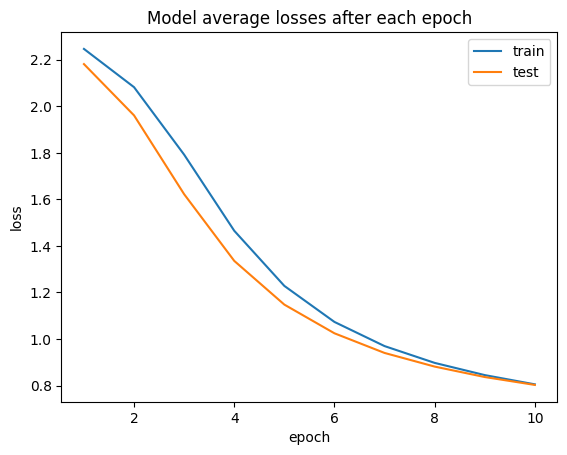

In [ ]:
# visualizing the loss curves
import matplotlib.pyplot as plt
plt.plot(range(1,epochs+1), train_losses)
plt.plot(range(1,epochs+1), test_losses)
plt.title('Model average losses after each epoch')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'])
plt.show()

In [ ]:
print(train_losses)
print(test_losses)


[2.246348145165677, 2.0819391351518854, 1.7919790021646251, 1.4650024886070283, 1.2280573097627554, 1.0732665957926688, 0.9694759828576656, 0.8973257141962234, 0.8448442498376882, 0.805093462406191]
[2.1811569830414594, 1.96069200023724, 1.6220812577350883, 1.335585369425974, 1.1476979506243565, 1.0244588373572963, 0.9400359828760669, 0.8814288973808289, 0.8365546438344724, 0.8026344379422011]


#__Group Exercise__:
Create another MLP with 3 hidden layers and then train that model on the Fashion-MNIST dataset using the SGD optimizer with a batch size of 64. If time permits, you can also train another MLP with the ADAM optimizer and observe if there is any change in training.

In [ ]:
# Step 1: load the Torch library and other utilities
#----------------------------------------------------


In [ ]:
# Step 2: load the dataset, ie, we are experimenting with Fashion-MNIST
#--------------------------------------------------------------------------------------------------


In [ ]:
# Step 3: Create your MLP Network (call it SimpleMLPv3) with 3 hidden layers
#--------------------------------------------------------------------------------------------------


class SimpleMLPv3(nn.Module):
  def __init__(self):
    super().__init__()
    # your network layer construction should take place here


    # You should have the following structure in your 3-hidden layer MLP
    '''
    num_of_neurons_input_layer      = 784
    num_of_neurons_1st_hidden_layer = 512
    num_of_neurons_2nd_hidden_layer = 256
    num_of_neurons_3rd_hidden_layer = 128
    num_of_neurons_output_layer     = 10
    # You should use ReLU activation function in each hidden layer

    num_of_neurons_output_layer     = 10 # usually this number should be equal to the total number of classes in your classification task
    '''

    self.flatten = nn.Flatten()
    # your code ...
    self.my_mlp = ...



  def forward(self, x):
    # your code for MLP forward pass should take place here
    output = self.flatten(x)                                                                # convert a 28x28 matrix of numbers (an image) into a contiguous vector of size 784 using .flatten() method
    output = self.my_mlp(output)
    return output




In [ ]:
# Step 4: Your training and testing functions (I copied it previous the previous demo. You don't need to change anything)
#--------------------------------------------------------------------------------------

def train_loop(dataloader, model, loss_fn, optimizer):

    size = len(dataloader.dataset)

    model.train()                   # set the model to training mode for best practices

    train_loss = 0

    for batch, (X, y) in enumerate(dataloader):

        # compute prediction and loss
        X = X.to(device)                  # send data to the GPU device (if available)
        y = y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        train_loss += loss.item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

    return train_loss/len(dataloader)

def test_loop(dataloader, model, loss_fn):

    model.eval()                    # set the model to evaluation mode for best practices

    size        = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
    # also serves to reduce unnecessary gradient computations and memory usage for tensors with requires_grad=True
    with torch.no_grad():
        for X, y in dataloader:

            X = X.to(device)                     # send data to the GPU device (if available)
            y = y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss


In [ ]:
# Step 5: prepare the DataLoader and select your optimizer and set the hyper-parameters for learning the model from DataLoader
#------------------------------------------------------------------------------------------------------------------------------
# Initialize your hyper-parameter and optimizer with appropriate values
# Use your dataset to prepare your DataLoaders one for training_data and one for test_data
# ...
# ...

print("SimpleMLPv3 model has been trained!")


In [ ]:
# visualizing the loss curves
